# Snapshot ensemble y SWA del clasificador K=70 entrenado con **SAM**

Mismo procedimiento que `cell_classifier_k70_haversine_aug_snapshot_ensemble.ipynb`, pero partiendo del mejor
checkpoint de `cell_classifier_k70_haversine_aug_sam.ipynb` (S42, época 14: top-1 0.351, error mediano 826 km) y
**usando también SAM en los ciclos**: cada ciclo sigue entrenando con LR **coseno con reinicio** y el mismo paso
SAM ($\rho$ leído del checkpoint) que la corrida base, y al final de cada ciclo (LR ≈ 0) se guarda un snapshot
(Huang et al., *Snapshot Ensembles: Train 1, get M for free*, ICLR 2017).

**Por qué este experimento.** El modelo final se entrenará con ~2M imágenes y solo entran 1–2 corridas completas,
así que interesa qué se puede sacar *de una sola corrida*. En `cell_classifier_k70_ensamble_corridas.ipynb`, S42 solo
(1.9 h) ya igualó al ensamble de dos semillas haversine (2.4 h) y al snapshot ensemble de H42 (0.343 / 846 km).
La duda es si SAM y los snapshots **se suman** o **se pisan**: SAM lleva a mínimos planos y anchos, así que los
reinicios podrían caer siempre en la misma cuenca y dar snapshots poco diversos.

**Dos formas de combinar los snapshots:**

- **Ensamble** (promedio de probabilidades): $M$ pasadas por imagen al predecir.
- **SWA** (Izmailov et al., *Averaging Weights Leads to Wider Optima and Better Generalization*, UAI 2018):
  promedio de los **pesos** de los mismos miembros, $\bar w = \frac{1}{M}\sum_m w_m$, en **un solo modelo**. Como las
  estadísticas de BatchNorm del modelo promediado no son el promedio de las estadísticas, se recalculan con una
  pasada por train. Funciona solo si los miembros están en la misma cuenca (lo que justamente se espera acá);
  si SWA sale mucho peor que los miembros, es que los ciclos los separaron demasiado.

Se reporta además una **comparación pareada por panorama** (bootstrap) de ensamble y SWA contra el modelo base, y
del ensamble contra el snapshot ensemble de H42, junto con el **costo** de los ciclos.

El ensamble promedia las probabilidades de los $M$ miembros y descompone la incerteza de cada imagen (Unidad 6):

- **total** $= H(\bar p)$ (entropía del promedio),
- **aleatórica** $= \frac{1}{M}\sum_m H(p_m)$ (lo que cada miembro considera ambiguo),
- **epistémica** $= H(\bar p) - \frac{1}{M}\sum_m H(p_m)$ (información mutua: **desacuerdo** entre miembros).

Todo se evalúa sobre la **validación global** (la misma de los otros notebooks). Ojo: esa validación ya se usó para
elegir el checkpoint base, así que estas métricas no reemplazan un test independiente; la comparación ensamble vs.
modelo base sí es justa (mismos datos, sin ajustar nada nuevo sobre validación).

Orden: **1. Configuración y datos → 2. Snapshots (con SAM) → 3. Métricas del ensamble, SWA y bootstrap →
4. Incerteza epistémica**.

## 1. Configuración y datos

In [1]:
from pathlib import Path
from io import BytesIO
import json
import math
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from datasets import Dataset as HFDataset, Image as HFImage
from PIL import Image
from tqdm.auto import tqdm
from contextlib import contextmanager
import time
from IPython.display import display

# Corrida base (relativa a la raíz del proyecto o absoluta).
RUTA_MODELO = "outputs/resnet18_IMAGENET_celdas_k70_haversine_aug_sam/20261112_114257_997479"
ARCHIVO_CHECKPOINT = "mejor_resnet18_celdas.pt"
NOMBRE_ENSAMBLE = "snapshot_ensemble"  # Subcarpeta de la corrida; con los mismos parámetros se retoma lo ya hecho.
RUTA_VALIDACION = "datasets/samples/data/validation/validation.parquet"

# Snapshots: cada ciclo dura EPOCAS_POR_CICLO épocas y el LR baja con coseno desde el máximo hasta 0.
CICLOS = 4  # Snapshots nuevos; el ensamble tiene CICLOS + 1 miembros si INCLUIR_BASE.
EPOCAS_POR_CICLO = 2
LR_MAX_CABEZA = 1e-3  # Mismos LR iniciales que el entrenamiento original.
LR_MAX_BACKBONE = 1e-4
INCLUIR_BASE = True  # El checkpoint original es el miembro 0 (también entra al promedio de pesos de SWA).
HACER_SWA = True  # Promedio de pesos de los miembros + recálculo de BatchNorm con una pasada por train.
# Snapshot ensemble de referencia (H42, sin SAM) para el bootstrap; None para omitirlo.
RUTA_SNAPSHOTS_REFERENCIA = "outputs/resnet18_IMAGENET_celdas_k70_haversine_aug/20261109_180324_467412/snapshot_ensemble"
B_BOOTSTRAP = 2000
SUBMUESTRA_TRAIN = None  # Entero para pruebas rápidas (usa solo esa cantidad de imágenes de train); None = todo.

COL_CLUSTER = "ind_cluster"
COLS_COORDENADAS = ["latitude", "longitude"]
RADIO_TIERRA_KM = 6371.0
N_BINS_ECE = 10
TOP_CELDAS = 10  # Celdas a listar en la tabla de las más inciertas.
MIN_IMAGENES_CELDA = 20  # Mínimo de imágenes de validación para entrar al ranking (con menos, el promedio es ruido).
BATCH_SIZE = 32
NUM_WORKERS = 0
SEMILLA = 42
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Ejecutá el notebook dentro del proyecto.")


def resolver_ruta(ruta):
    p = Path(ruta).expanduser()
    return (p if p.is_absolute() else raiz / p).resolve()


ruta_modelo = resolver_ruta(RUTA_MODELO)
ruta_checkpoint = ruta_modelo / ARCHIVO_CHECKPOINT
ruta_validacion = resolver_ruta(RUTA_VALIDACION)
ruta_salida = ruta_modelo / NOMBRE_ENSAMBLE
for archivo in (ruta_checkpoint, ruta_modelo / "prototipos.csv", ruta_validacion):
    if not archivo.is_file():
        raise FileNotFoundError(archivo)
assert CICLOS >= 1 and EPOCAS_POR_CICLO >= 1 and (CICLOS + INCLUIR_BASE) >= 2
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
device = torch.device(DISPOSITIVO)

# Si la carpeta ya existe, tiene que corresponder a los mismos parámetros (para retomar sin mezclar ensambles).
parametros = {"checkpoint_base": str(ruta_checkpoint), "ciclos": CICLOS, "epocas_por_ciclo": EPOCAS_POR_CICLO,
              "lr_max_cabeza": LR_MAX_CABEZA, "lr_max_backbone": LR_MAX_BACKBONE, "incluir_base": INCLUIR_BASE,
              "submuestra_train": SUBMUESTRA_TRAIN, "batch_size": BATCH_SIZE, "semilla": SEMILLA,
              "sam_en_ciclos": True}
ruta_parametros = ruta_salida / "parametros_ensamble.json"
if ruta_parametros.is_file():
    previos = json.loads(ruta_parametros.read_text(encoding="utf-8"))
    if previos != parametros:
        raise ValueError(f"{ruta_salida} se creó con otros parámetros: {previos}. Cambiá NOMBRE_ENSAMBLE.")
ruta_salida.mkdir(parents=True, exist_ok=True)
ruta_parametros.write_text(json.dumps(parametros, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Base: {ruta_checkpoint}\nSalida: {ruta_salida}\nDispositivo: {device}")

c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Base: C:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18_IMAGENET_celdas_k70_haversine_aug_sam\20261112_114257_997479\mejor_resnet18_celdas.pt
Salida: C:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18_IMAGENET_celdas_k70_haversine_aug_sam\20261112_114257_997479\snapshot_ensemble
Dispositivo: cuda


### Modelo base, prototipos y datos

Se reconstruye la arquitectura de la corrida (ResNet18 + `Dropout` + `Linear` de 70 salidas) y se reutilizan su
configuración (train, τ, dropout, weight decay, augmentation, $\rho$ de SAM y $\gamma$ de la focal si la hubiera) y sus prototipos. Las etiquetas y las distancias a los
prototipos se calculan desde las coordenadas, igual que en el entrenamiento.

In [2]:
checkpoint_base = torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)
cfg = checkpoint_base["config"]
if cfg.get("arquitectura") != "resnet18" or cfg.get("tarea") != "clasificacion_celdas_voronoi":
    raise ValueError("El checkpoint no es un clasificador de celdas ResNet18.")
TAU_KM, DROPOUT, WEIGHT_DECAY = cfg["tau_km"], cfg["dropout"], cfg["weight_decay"]
TAMANO_IMAGEN = cfg["tamano_imagen"]
RHO_SAM = cfg.get("rho_sam", 0.0)  # 0 = la corrida base no usó SAM: los ciclos usan AdamW solo.
GAMMA_FOCAL = cfg.get("gamma_focal", 0.0)  # 0 = CE haversine (la de la corrida SAM).
print(f"Ciclos con: rho SAM = {RHO_SAM}, gamma focal = {GAMMA_FOCAL}, tau = {TAU_KM} km")

prototipos = pd.read_csv(ruta_modelo / "prototipos.csv").sort_values(COL_CLUSTER).reset_index(drop=True)
NUM_CLASES = len(prototipos)
assert NUM_CLASES == cfg["num_clases"] and (prototipos[COL_CLUSTER].to_numpy() == np.arange(NUM_CLASES)).all()
coords_prototipos = prototipos[["lat", "lon"]].to_numpy(dtype=np.float64)
ruta_proto_original = Path(cfg["prototipos"]["ruta"])
if ruta_proto_original.is_file():
    if hashlib.sha256(ruta_proto_original.read_bytes()).hexdigest() != cfg["prototipos"]["sha256"]:
        raise ValueError(f"{ruta_proto_original} cambió desde el entrenamiento.")


def to_xyz(lat, lon):
    lat, lon = np.radians(lat), np.radians(lon)
    return np.column_stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


centroides = to_xyz(coords_prototipos[:, 0], coords_prototipos[:, 1])
dist_proto = haversine_km(coords_prototipos[:, None, 0], coords_prototipos[:, None, 1],
                          coords_prototipos[None, :, 0], coords_prototipos[None, :, 1])


def metadatos(dataset):
    tabla = dataset.select_columns(["image_id", "panoid", "country_code", *COLS_COORDENADAS]).to_pandas()
    lat, lon = (tabla[c].to_numpy(dtype=np.float64) for c in COLS_COORDENADAS)
    if not (np.isfinite(lat) & np.isfinite(lon)).all():
        raise ValueError("Hay coordenadas inválidas.")
    tabla[COL_CLUSTER] = (to_xyz(lat, lon) @ centroides.T).argmax(axis=1)
    distancias = haversine_km(lat[:, None], lon[:, None], coords_prototipos[None, :, 0], coords_prototipos[None, :, 1])
    assert (distancias.argmin(axis=1) == tabla[COL_CLUSTER].to_numpy()).all()
    return tabla, distancias


cache_hf = str(raiz / ".cache/modeling/hf_celdas")
datos_train = HFDataset.from_parquet(cfg["ruta_train"], cache_dir=cache_hf).cast_column("image", HFImage(decode=False))
datos_val = HFDataset.from_parquet(str(ruta_validacion), cache_dir=cache_hf).cast_column("image", HFImage(decode=False))
meta_train, dist_train = metadatos(datos_train)
meta_val, dist_val = metadatos(datos_val)
if set(meta_train["panoid"]) & set(meta_val["panoid"]):
    raise ValueError("Fuga de datos: panoramas compartidos entre train y validación.")
real = meta_val[COL_CLUSTER].to_numpy()

pesos_imagenet = models.ResNet18_Weights.IMAGENET1K_V1.transforms()
normalizar = transforms.Normalize(pesos_imagenet.mean, pesos_imagenet.std)
# Mismo augmentation que la corrida base (solo en train).
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(TAMANO_IMAGEN, scale=(0.6, 1.0), ratio=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0),
    transforms.ToTensor(), normalizar,
])
transform_val = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN), transforms.CenterCrop(TAMANO_IMAGEN), transforms.ToTensor(), normalizar,
])
if cfg["preprocesamiento_train"] != repr(transform_train) or cfg["preprocesamiento_val"] != repr(transform_val):
    raise ValueError("El preprocesamiento no coincide con el de la corrida base.")


class Imagenes(Dataset):
    # Devuelve (imagen, distancias en km a los K prototipos).
    def __init__(self, datos, distancias, transform):
        self.datos, self.transform = datos, transform
        self.distancias = torch.from_numpy(distancias).float()

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, idx):
        contenido = self.datos[int(idx)]["image"]
        fuente = BytesIO(contenido["bytes"]) if contenido.get("bytes") is not None else resolver_ruta(contenido["path"])
        with Image.open(fuente) as imagen:
            return self.transform(imagen.convert("RGB")), self.distancias[idx]


dataset_train = Imagenes(datos_train, dist_train, transform_train)
if SUBMUESTRA_TRAIN:
    dataset_train = Subset(dataset_train, np.random.default_rng(SEMILLA).permutation(len(dataset_train))[:SUBMUESTRA_TRAIN])
loader_val = DataLoader(Imagenes(datos_val, dist_val, transform_val), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")


def construir_modelo():
    m = models.resnet18(weights=None)
    m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, NUM_CLASES))
    return m.to(device)


modelo = construir_modelo()
modelo.load_state_dict(checkpoint_base["model_state_dict"])
print(f"Base: época {checkpoint_base['epoca']} (loss val={checkpoint_base['loss_validation']:.4f})")
print(f"Train: {len(dataset_train):,} imágenes; validación: {len(meta_val):,} imágenes, {meta_val['panoid'].nunique():,} panoramas")

Ciclos con: rho SAM = 0.05, gamma focal = 0.0, tau = 300 km
Base: época 14 (loss val=2.3301)
Train: 20,000 imágenes; validación: 5,332 imágenes, 1,333 panoramas


## 2. Snapshots

Cada ciclo arranca desde el snapshot anterior (el primero, desde el checkpoint base) con un optimizador AdamW nuevo
(mismos LR máximos, weight decay, loss y **paso SAM** que la corrida original) y un LR que baja con **coseno** paso a
paso hasta 0 en `EPOCAS_POR_CICLO` épocas. Al final del ciclo se guardan `snapshot_k.pt` y los logits de validación
`logits_k.npy`. Si esos archivos ya existen se reutilizan: la celda puede interrumpirse y retomarse.

Los snapshots no se eligen con validación (se guardan siempre al final de cada ciclo).

En la segunda pasada de SAM (pesos perturbados) no se actualizan las estadísticas de BatchNorm, igual que en el entrenamiento base. Se guarda la duración de cada ciclo para estimar el costo.

In [3]:
def loss_haversine(logits, distancias):
    # CE contra el target blando q = softmax(-d / τ), igual que en la corrida base; con GAMMA_FOCAL > 0, cada término
    # se modula por (1 - p_k)^γ (focal con target haversine).
    q = torch.softmax(-distancias / TAU_KM, dim=1)
    log_p = torch.log_softmax(logits.float(), dim=1)
    if GAMMA_FOCAL:
        return -(q * (1 - log_p.exp()) ** GAMMA_FOCAL * log_p).sum(dim=1).mean()
    return -(q * log_p).sum(dim=1).mean()


class SAM:
    # Sharpness-Aware Minimization (Foret et al., 2021) sobre AdamW, igual que en la corrida base.
    def __init__(self, optimizador_base, rho):
        self.base, self.rho, self.perturbaciones = optimizador_base, rho, {}

    def _con_gradiente(self):
        return [p for g in self.base.param_groups for p in g["params"] if p.grad is not None]

    @torch.no_grad()
    def primer_paso(self):
        # w -> w + e, con e = rho * g / ||g|| (norma L2 global).
        params = self._con_gradiente()
        norma = torch.norm(torch.stack([p.grad.norm(2) for p in params]), 2)
        escala = self.rho / (norma + 1e-12)
        for p in params:
            e = p.grad * escala
            p.add_(e)
            self.perturbaciones[p] = e
        self.base.zero_grad(set_to_none=True)

    @torch.no_grad()
    def segundo_paso(self):
        # Vuelve a w y da el paso de AdamW con el gradiente calculado en w + e.
        for p, e in self.perturbaciones.items():
            p.sub_(e)
        self.perturbaciones = {}
        self.base.step()
        self.base.zero_grad(set_to_none=True)


@contextmanager
def bn_sin_actualizar(red):
    # Momentum 0 en BatchNorm durante la pasada perturbada: no cambian las estadísticas acumuladas.
    bns = [m for m in red.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    momentos = [m.momentum for m in bns]
    for m in bns:
        m.momentum = 0.0
    try:
        yield
    finally:
        for m, momento in zip(bns, momentos):
            m.momentum = momento


@torch.inference_mode()
def logits_validacion(m):
    m.eval()
    salidas = [m(imagenes.to(device, non_blocking=True)).float().cpu() for imagenes, _ in tqdm(loader_val, desc="Validación")]
    return torch.cat(salidas).numpy().astype(np.float64)


def entrenar_ciclo(m, ciclo):
    optimizador = torch.optim.AdamW([
        {"params": m.fc.parameters(), "lr": LR_MAX_CABEZA},
        {"params": [p for n, p in m.named_parameters() if not n.startswith("fc.")], "lr": LR_MAX_BACKBONE},
    ], weight_decay=WEIGHT_DECAY)
    loader = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                        generator=torch.Generator().manual_seed(SEMILLA + ciclo), pin_memory=device.type == "cuda")
    pasos_totales = EPOCAS_POR_CICLO * len(loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizador, lambda paso: 0.5 * (1 + math.cos(math.pi * paso / pasos_totales)))
    sam = SAM(optimizador, RHO_SAM) if RHO_SAM > 0 else None
    m.train()
    inicio = time.perf_counter()
    for epoca in range(1, EPOCAS_POR_CICLO + 1):
        total, n = 0.0, 0
        for imagenes, distancias in tqdm(loader, desc=f"Ciclo {ciclo} época {epoca}"):
            imagenes, distancias = imagenes.to(device, non_blocking=True), distancias.to(device, non_blocking=True)
            loss = loss_haversine(m(imagenes), distancias)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss no finita.")
            optimizador.zero_grad(set_to_none=True)
            loss.backward()
            if sam is None:
                optimizador.step()
            else:
                sam.primer_paso()
                with bn_sin_actualizar(m):
                    loss_haversine(m(imagenes), distancias).backward()
                sam.segundo_paso()
            scheduler.step()
            total += loss.item() * len(imagenes)
            n += len(imagenes)
        print(f"  ciclo {ciclo}, época {epoca}: loss train={total / n:.4f}, lr cabeza al final={optimizador.param_groups[0]['lr']:.2e}")
    return time.perf_counter() - inicio


def acc_top1(logits):
    return (logits.argmax(axis=1) == real).mean()


miembros = {}  # nombre -> logits de validación
segundos_ciclo = {}
if INCLUIR_BASE:
    ruta_logits_base = ruta_salida / "logits_0_base.npy"
    if not ruta_logits_base.is_file():
        np.save(ruta_logits_base, logits_validacion(modelo))
    miembros["base"] = np.load(ruta_logits_base)
    print(f"Miembro base: accuracy top-1 = {acc_top1(miembros['base']):.4f}")

for ciclo in range(1, CICLOS + 1):
    ruta_snapshot, ruta_logits = ruta_salida / f"snapshot_{ciclo}.pt", ruta_salida / f"logits_{ciclo}.npy"
    if ruta_snapshot.is_file():
        guardado = torch.load(ruta_snapshot, map_location="cpu", weights_only=True)
        modelo.load_state_dict(guardado["model_state_dict"])
        segundos_ciclo[ciclo] = guardado.get("segundos", float("nan"))
        print(f"Snapshot {ciclo}: reutilizado de {ruta_snapshot.name}")
    else:
        torch.manual_seed(SEMILLA + ciclo)  # Máscaras de dropout y crops distintos en cada ciclo.
        segundos_ciclo[ciclo] = entrenar_ciclo(modelo, ciclo)
        torch.save({"model_state_dict": modelo.state_dict(), "ciclo": ciclo, "parametros": parametros,
                    "config_base": cfg, "segundos": segundos_ciclo[ciclo]}, ruta_snapshot)
    if not ruta_logits.is_file():
        np.save(ruta_logits, logits_validacion(modelo))
    miembros[f"snapshot_{ciclo}"] = np.load(ruta_logits)
    print(f"Snapshot {ciclo}: accuracy top-1 = {acc_top1(miembros[f'snapshot_{ciclo}']):.4f}")
horas_base = pd.read_csv(ruta_modelo / "historial.csv")["segundos"].sum() / 3600
horas_ciclos = sum(segundos_ciclo.values()) / 3600
print(f"Costo: corrida base {horas_base:.2f} h + ciclos {horas_ciclos:.2f} h "
      f"({60 * horas_ciclos / CICLOS:.1f} min por ciclo)")
del checkpoint_base

Validación: 100%|██████████| 167/167 [00:43<00:00,  3.85it/s]


Miembro base: accuracy top-1 = 0.3509


Ciclo 1 época 1: 100%|██████████| 625/625 [05:28<00:00,  1.90it/s]


  ciclo 1, época 1: loss train=1.3473, lr cabeza al final=5.00e-04


Ciclo 1 época 2: 100%|██████████| 625/625 [05:11<00:00,  2.01it/s]


  ciclo 1, época 2: loss train=1.1644, lr cabeza al final=0.00e+00


... (16 outputs left out)

Ciclo 4 época 2: 100%|██████████| 625/625 [04:59<00:00,  2.09it/s]


  ciclo 4, época 2: loss train=1.0364, lr cabeza al final=0.00e+00


Validación: 100%|██████████| 167/167 [00:40<00:00,  4.10it/s]


Snapshot 4: accuracy top-1 = 0.3426
Costo: corrida base 1.89 h + ciclos 0.70 h (10.5 min por ciclo)


## 3. Métricas del ensamble, SWA y bootstrap

Para cada miembro y para el ensamble (promedio de probabilidades): accuracy top-1/top-5, NLL (CE contra la celda
real), ECE, error en km del argmax y de la predicción por mínimo riesgo. Se agregan:

- **Baseline NoCycle**: ensamble de los checkpoints `mejor` y `ultimo` (fin del early stopping) de la corrida original,
  es decir, snapshots de un schedule estándar sin reinicios (Tabla 1 del paper).
- **Ensamble acumulado** en las dos direcciones: desde el primer miembro (como las Figuras 7–9 del paper) y con los
  **últimos m** (como recomienda la sección 4.3, porque los snapshots más entrenados suelen ser los mejores).
- **Diversidad**: correlación de las salidas softmax entre pares de miembros (Figura 6 del paper) y fracción de
  imágenes en que dos miembros predicen distinta celda.

In [4]:
# Baseline NoCycle: checkpoint 'ultimo' de la corrida original + el base ('mejor').
ruta_ultimo = ruta_modelo / "ultimo_resnet18_celdas.pt"
ruta_logits_ultimo = ruta_salida / "logits_ultimo_original.npy"
logits_ultimo = None
if ruta_ultimo.is_file():
    if not ruta_logits_ultimo.is_file():
        modelo_ultimo = construir_modelo()
        ckpt_ultimo = torch.load(ruta_ultimo, map_location="cpu", weights_only=True)
        modelo_ultimo.load_state_dict(ckpt_ultimo["model_state_dict"])
        print(f"Checkpoint 'ultimo' de la corrida original: época {ckpt_ultimo['epoca']}")
        np.save(ruta_logits_ultimo, logits_validacion(modelo_ultimo))
        del modelo_ultimo, ckpt_ultimo
    logits_ultimo = np.load(ruta_logits_ultimo)
else:
    print(f"No está {ruta_ultimo.name}: se omite el baseline NoCycle.")

Checkpoint 'ultimo' de la corrida original: época 18


Validación: 100%|██████████| 167/167 [00:41<00:00,  4.05it/s]


,accuracy_top1,accuracy_top5,nll,ece,error_medio_km,error_mediano_km,accuracy_top1_mbr,error_medio_km_mbr,error_mediano_km_mbr
base,0.3509,0.7911,2.1050,0.0354,2857.7976,826.0714,0.3200,2694.3635,848.6728
snapshot_1,0.3483,0.7838,2.1396,0.0484,2835.9797,830.0040,0.3258,2669.1147,826.5198
snapshot_2,0.3451,0.7811,2.1598,0.0531,2878.1539,843.0596,0.3224,2724.8787,840.8208
snapshot_3,0.3479,0.7798,2.1722,0.0597,2878.2098,834.3276,0.3295,2677.6735,828.7422
snapshot_4,0.3426,0.7712,2.1834,0.0619,2846.1515,857.8053,0.3198,2685.0880,856.5820
ultimo original,0.3468,0.7866,2.1213,0.0411,2843.5494,826.5220,0.3196,2663.4810,827.1131
NoCycle (base + ultimo),0.3515,0.7877,2.1014,0.0323,2845.1203,824.6379,0.3215,2647.9178,832.2168
ensamble snapshots (M=5),0.3616,0.7894,2.0877,0.0317,2774.2116,804.7958,0.3305,2591.4260,819.2465


Ensamble acumulado desde el primer miembro:


,accuracy_top1,accuracy_top5,nll,error_mediano_km,error_medio_km_mbr
miembros,,,,,
1,0.3509,0.7911,2.1050,826.0714,2694.3635
2,0.3535,0.7899,2.0916,820.2117,2630.0611
3,0.3565,0.7914,2.0881,811.0701,2610.4583
4,0.3597,0.7907,2.0886,807.2214,2622.6567
5,0.3616,0.7894,2.0877,804.7958,2591.4260


Ensamble de los últimos m miembros:


,accuracy_top1,accuracy_top5,nll,error_mediano_km,error_medio_km_mbr
miembros,,,,,
1,0.3426,0.7712,2.1834,857.8053,2685.0880
2,0.3530,0.7774,2.1422,826.4369,2635.5756
3,0.3586,0.7839,2.1233,814.6548,2650.2905
4,0.3567,0.7896,2.1059,812.9455,2632.4214
5,0.3616,0.7894,2.0877,804.7958,2591.4260


Desacuerdo de predicción (argmax) entre miembros:


,base,snapshot_1,snapshot_2,snapshot_3,snapshot_4
base,0.000,0.266,0.300,0.318,0.329
snapshot_1,0.266,0.000,0.265,0.298,0.306
snapshot_2,0.300,0.265,0.000,0.268,0.295
snapshot_3,0.318,0.298,0.268,0.000,0.273
snapshot_4,0.329,0.306,0.295,0.273,0.000


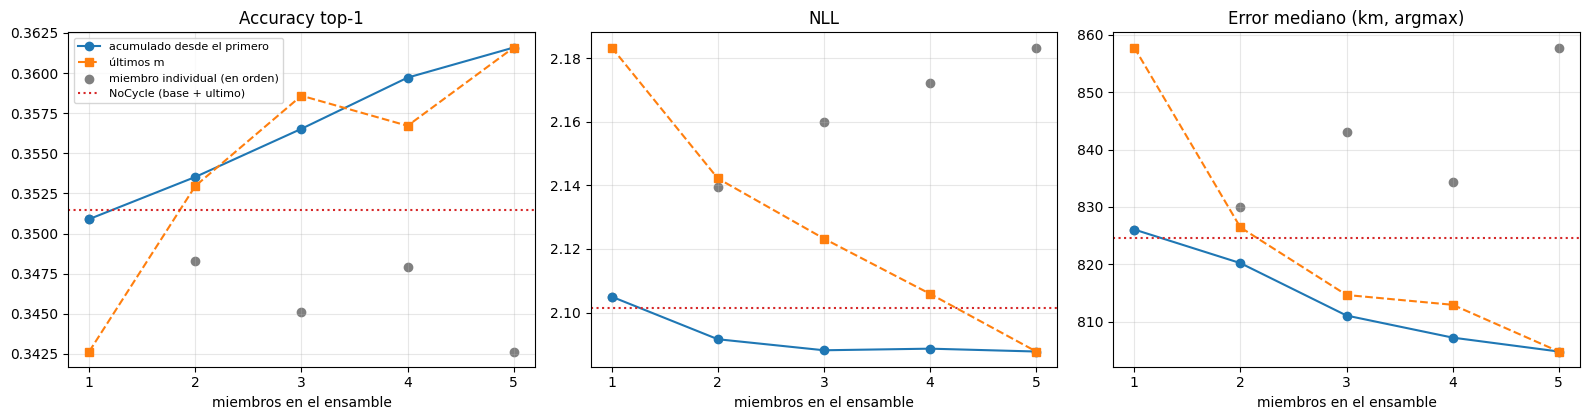

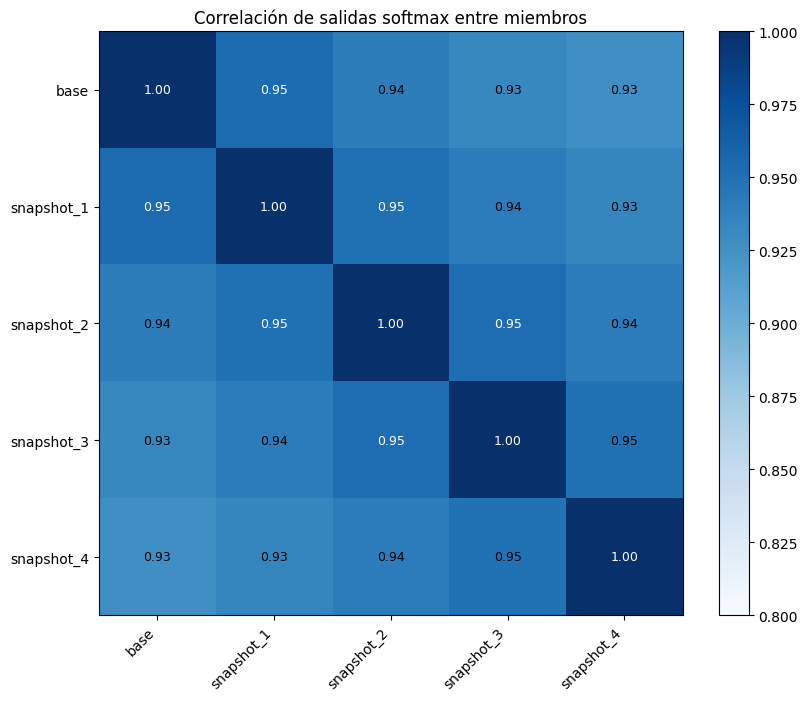

In [5]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def ece_top_label(p, y, n_bins=N_BINS_ECE):
    conf, acierto = p.max(axis=1), p.argmax(axis=1) == y
    bin_id = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return float(sum((bin_id == b).mean() * abs(acierto[bin_id == b].mean() - conf[bin_id == b].mean())
                     for b in range(n_bins) if (bin_id == b).any()))


def metricas(p, y=real):
    pred = p.argmax(axis=1)
    pred_mbr = (p @ dist_proto).argmin(axis=1)
    err, err_mbr = dist_val[np.arange(len(y)), pred], dist_val[np.arange(len(y)), pred_mbr]
    top5 = np.argsort(-p, axis=1)[:, :5]
    return {
        "accuracy_top1": (pred == y).mean(), "accuracy_top5": (top5 == y[:, None]).any(axis=1).mean(),
        "nll": -np.log(np.clip(p[np.arange(len(y)), y], 1e-12, None)).mean(), "ece": ece_top_label(p, y),
        "error_medio_km": err.mean(), "error_mediano_km": np.median(err),
        "accuracy_top1_mbr": (pred_mbr == y).mean(),
        "error_medio_km_mbr": err_mbr.mean(), "error_mediano_km_mbr": np.median(err_mbr),
    }


nombres = list(miembros)
probs = np.stack([softmax(miembros[n]) for n in nombres])  # (M, N, K)
p_ens = probs.mean(axis=0)
M = len(nombres)

filas = {n: metricas(probs[i]) for i, n in enumerate(nombres)}
if logits_ultimo is not None:
    filas["ultimo original"] = metricas(softmax(logits_ultimo))
    if INCLUIR_BASE:
        filas["NoCycle (base + ultimo)"] = metricas((probs[0] + softmax(logits_ultimo)) / 2)
filas[f"ensamble snapshots (M={M})"] = metricas(p_ens)
tabla_miembros = pd.DataFrame(filas).T
display(tabla_miembros.round(4))

# Acumulado desde el primer miembro (Figuras 7-9 del paper) y con los últimos m (sección 4.3).
acumulado = pd.DataFrame({m: metricas(probs[:m].mean(axis=0)) for m in range(1, M + 1)}).T
ultimos_m = pd.DataFrame({m: metricas(probs[M - m:].mean(axis=0)) for m in range(1, M + 1)}).T
acumulado.index.name = ultimos_m.index.name = "miembros"
columnas_resumen = ["accuracy_top1", "accuracy_top5", "nll", "error_mediano_km", "error_medio_km_mbr"]
print("Ensamble acumulado desde el primer miembro:")
display(acumulado[columnas_resumen].round(4))
print("Ensamble de los últimos m miembros:")
display(ultimos_m[columnas_resumen].round(4))

# Diversidad: correlación de softmax entre pares (Figura 6 del paper) y desacuerdo de argmax.
correlacion = pd.DataFrame(np.corrcoef(probs.reshape(M, -1)), index=nombres, columns=nombres)
pred_miembros = probs.argmax(axis=2)
desacuerdo = pd.DataFrame([[(pred_miembros[i] != pred_miembros[j]).mean() for j in range(M)] for i in range(M)],
                          index=nombres, columns=nombres)
print("Desacuerdo de predicción (argmax) entre miembros:")
display(desacuerdo.round(3))

tabla_miembros.to_csv(ruta_salida / "metricas_miembros_y_ensamble.csv")
acumulado.to_csv(ruta_salida / "metricas_ensamble_acumulado.csv")
ultimos_m.to_csv(ruta_salida / "metricas_ensamble_ultimos_m.csv")
correlacion.to_csv(ruta_salida / "correlacion_softmax_miembros.csv")
(ruta_salida / "metricas_ensamble.json").write_text(
    json.dumps({k: float(v) for k, v in filas[f"ensamble snapshots (M={M})"].items()}, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col, titulo in ((axes[0], "accuracy_top1", "Accuracy top-1"), (axes[1], "nll", "NLL"),
                        (axes[2], "error_mediano_km", "Error mediano (km, argmax)")):
    ax.plot(acumulado.index, acumulado[col], marker="o", label="acumulado desde el primero")
    ax.plot(ultimos_m.index, ultimos_m[col], marker="s", linestyle="--", label="últimos m")
    ax.scatter(range(1, M + 1), [filas[n][col] for n in nombres], color="gray", label="miembro individual (en orden)")
    if "NoCycle (base + ultimo)" in filas:
        ax.axhline(filas["NoCycle (base + ultimo)"][col], color="tab:red", linestyle=":", label="NoCycle (base + ultimo)")
    ax.set(xlabel="miembros en el ensamble", title=titulo, xticks=range(1, M + 1))
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ruta_salida / "ensamble_acumulado.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(1.3 * M + 2, 1.1 * M + 1.5))
im = ax.imshow(correlacion.to_numpy(), cmap="Blues", vmin=min(0.8, correlacion.to_numpy().min()), vmax=1)
ax.set(xticks=range(M), yticks=range(M), title="Correlación de salidas softmax entre miembros")
ax.set_xticklabels(nombres, rotation=45, ha="right")
ax.set_yticklabels(nombres)
for i in range(M):
    for j in range(M):
        ax.text(j, i, f"{correlacion.iat[i, j]:.2f}", ha="center", va="center",
                color="white" if correlacion.iat[i, j] > 0.95 else "black", fontsize=9)
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(ruta_salida / "correlacion_softmax_miembros.png", dpi=160)
plt.show()

### SWA: promedio de pesos

Se promedian los pesos de los mismos miembros del ensamble (incluido el base si `INCLUIR_BASE`) y se recalculan las
estadísticas de BatchNorm con una pasada por **train** (con su augmentation, sin gradientes,
`torch.optim.swa_utils.update_bn`). El resultado es **un solo modelo**: mismo costo de inferencia que el base.
Se guardan `swa.pt` y `logits_swa.npy` (si existen, se reutilizan).

In [6]:
p_swa = None
if HACER_SWA:
    ruta_swa, ruta_logits_swa = ruta_salida / "swa.pt", ruta_salida / "logits_swa.npy"
    if not ruta_logits_swa.is_file():
        estados = ([torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)["model_state_dict"]]
                   if INCLUIR_BASE else [])
        estados += [torch.load(ruta_salida / f"snapshot_{c}.pt", map_location="cpu", weights_only=True)["model_state_dict"]
                    for c in range(1, CICLOS + 1)]
        promedio = {k: (torch.stack([e[k].float() for e in estados]).mean(dim=0) if estados[0][k].is_floating_point()
                        else estados[0][k].clone()) for k in estados[0]}
        modelo_swa = construir_modelo()
        modelo_swa.load_state_dict(promedio)
        loader_bn = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                               generator=torch.Generator().manual_seed(SEMILLA), pin_memory=device.type == "cuda")
        torch.manual_seed(SEMILLA)
        torch.optim.swa_utils.update_bn(tqdm(loader_bn, desc="BatchNorm SWA"), modelo_swa, device=device)
        torch.save({"model_state_dict": modelo_swa.state_dict(), "miembros": len(estados), "parametros": parametros,
                    "config_base": cfg}, ruta_swa)
        np.save(ruta_logits_swa, logits_validacion(modelo_swa))
        del modelo_swa, estados, promedio
    p_swa = softmax(np.load(ruta_logits_swa))
    filas[f"SWA (M={M})"] = metricas(p_swa)

# Referencia: snapshot ensemble de H42 (sin SAM).
p_ref = None
if RUTA_SNAPSHOTS_REFERENCIA:
    ruta_ref = resolver_ruta(RUTA_SNAPSHOTS_REFERENCIA)
    archivos_ref = sorted(ruta_ref.glob("logits_[0-9]*.npy"))
    if archivos_ref:
        p_ref = np.mean([softmax(np.load(f)) for f in archivos_ref], axis=0)
        filas[f"referencia: snapshots H42 (M={len(archivos_ref)})"] = metricas(p_ref)
tabla_final = pd.DataFrame(filas).T
display(tabla_final.round(4))
tabla_final.to_csv(ruta_salida / "metricas_miembros_ensamble_y_swa.csv")

Validación: 100%|██████████| 167/167 [00:40<00:00,  4.13it/s]


,accuracy_top1,accuracy_top5,nll,ece,error_medio_km,error_mediano_km,accuracy_top1_mbr,error_medio_km_mbr,error_mediano_km_mbr
base,0.3509,0.7911,2.1050,0.0354,2857.7976,826.0714,0.3200,2694.3635,848.6728
snapshot_1,0.3483,0.7838,2.1396,0.0484,2835.9797,830.0040,0.3258,2669.1147,826.5198
snapshot_2,0.3451,0.7811,2.1598,0.0531,2878.1539,843.0596,0.3224,2724.8787,840.8208
snapshot_3,0.3479,0.7798,2.1722,0.0597,2878.2098,834.3276,0.3295,2677.6735,828.7422
snapshot_4,0.3426,0.7712,2.1834,0.0619,2846.1515,857.8053,0.3198,2685.0880,856.5820
ultimo original,0.3468,0.7866,2.1213,0.0411,2843.5494,826.5220,0.3196,2663.4810,827.1131
NoCycle (base + ultimo),0.3515,0.7877,2.1014,0.0323,2845.1203,824.6379,0.3215,2647.9178,832.2168
ensamble snapshots (M=5),0.3616,0.7894,2.0877,0.0317,2774.2116,804.7958,0.3305,2591.4260,819.2465
SWA (M=5),0.3560,0.7886,2.1153,0.0482,2787.9642,815.7872,0.3297,2643.2705,821.1760
referencia: snapshots H42 (M=5),0.3426,0.7725,2.2166,0.0506,2912.6237,845.9433,0.3168,2705.5404,855.3802


### Bootstrap pareado por panorama

Diferencias A − B en accuracy top-1 (puntos) y error mediano (km, argmax) con intervalo del 95%, remuestreando
panoramas con reposición (las 4 vistas de un panorama no son independientes). Todas las comparaciones usan los
mismos remuestreos.

In [7]:
candidatos = {"ensamble": p_ens, "base": probs[0] if INCLUIR_BASE else None, "SWA": p_swa,
              "snapshots H42": p_ref}
candidatos = {n: p for n, p in candidatos.items() if p is not None}
comparaciones = [(a, b) for a, b in (("ensamble", "base"), ("SWA", "base"), ("ensamble", "SWA"),
                                     ("ensamble", "snapshots H42"), ("SWA", "snapshots H42"))
                 if a in candidatos and b in candidatos]
idx = np.arange(len(real))
pred_c = {n: p.argmax(axis=1) for n, p in candidatos.items()}
acierto_c = {n: pred_c[n] == real for n in candidatos}
km_c = {n: dist_val[idx, pred_c[n]] for n in candidatos}
_, inverso = np.unique(meta_val["panoid"].to_numpy(), return_inverse=True)
n_pan = inverso.max() + 1
filas_por_panorama = [np.flatnonzero(inverso == i) for i in range(n_pan)]
rng_boot = np.random.default_rng(SEMILLA)
difs = np.empty((B_BOOTSTRAP, len(comparaciones), 2))
for b in tqdm(range(B_BOOTSTRAP), desc="Bootstrap"):
    ix = np.concatenate([filas_por_panorama[i] for i in rng_boot.integers(0, n_pan, n_pan)])
    acc = {n: acierto_c[n][ix].mean() for n in candidatos}
    med = {n: np.median(km_c[n][ix]) for n in candidatos}
    for j, (a, c) in enumerate(comparaciones):
        difs[b, j] = acc[a] - acc[c], med[a] - med[c]
filas_boot = []
for j, (a, c) in enumerate(comparaciones):
    lo, hi = np.percentile(difs[:, j], [2.5, 97.5], axis=0)
    filas_boot.append({"comparacion": f"{a} − {c}",
                       "dif_accuracy_pts": 100 * (acierto_c[a].mean() - acierto_c[c].mean()),
                       "ic95_acc_inf": 100 * lo[0], "ic95_acc_sup": 100 * hi[0],
                       "dif_mediana_km": np.median(km_c[a]) - np.median(km_c[c]),
                       "ic95_km_inf": lo[1], "ic95_km_sup": hi[1],
                       "ganadas": int((acierto_c[a] & ~acierto_c[c]).sum()),
                       "perdidas": int((~acierto_c[a] & acierto_c[c]).sum())})
bootstrap = pd.DataFrame(filas_boot).set_index("comparacion")
bootstrap.to_csv(ruta_salida / "bootstrap_comparaciones.csv")
display(bootstrap.round(2))
(ruta_salida / "costo.json").write_text(json.dumps(
    {"horas_corrida_base": horas_base, "horas_ciclos": horas_ciclos,
     "segundos_por_ciclo": {str(k): v for k, v in segundos_ciclo.items()}}, indent=2), encoding="utf-8")

Bootstrap: 100%|██████████| 2000/2000 [00:02<00:00, 935.22it/s] 


,dif_accuracy_pts,ic95_acc_inf,ic95_acc_sup,dif_mediana_km,ic95_km_inf,ic95_km_sup,ganadas,perdidas
comparacion,,,,,,,,
ensamble − base,1.07,0.21,1.91,-21.28,-48.68,-4.74,268,211
SWA − base,0.51,-0.34,1.33,-10.28,-35.02,5.48,257,230
ensamble − SWA,0.56,0.19,0.96,-10.99,-26.17,-1.94,70,40
ensamble − snapshots H42,1.89,0.71,3.09,-41.15,-75.09,-18.54,560,459
SWA − snapshots H42,1.33,0.15,2.51,-30.16,-60.20,-6.17,542,471


226

## 4. Incerteza epistémica

Descomposición por imagen (en nats): total $H(\bar p)$, aleatórica $\overline{H(p_m)}$ y epistémica
$H(\bar p) - \overline{H(p_m)}$. Controles: la incerteza debería ser mayor en los errores que en los aciertos, y
descartar primero las imágenes más inciertas debería subir la accuracy de las que quedan (predicción selectiva).

**Limitación:** los snapshots salen de una única corrida, así que su diversidad es menor que la de un ensamble de
entrenamientos independientes y tienden a **subestimar** la incerteza epistémica. Sirve para ordenar imágenes y celdas
por dificultad relativa, no como un valor absoluto.

,incerteza_total,incerteza_aleatorica,incerteza_epistemica
acierto,,,
errores,2.0592,2.0021,0.0571
aciertos,1.5917,1.5504,0.0413


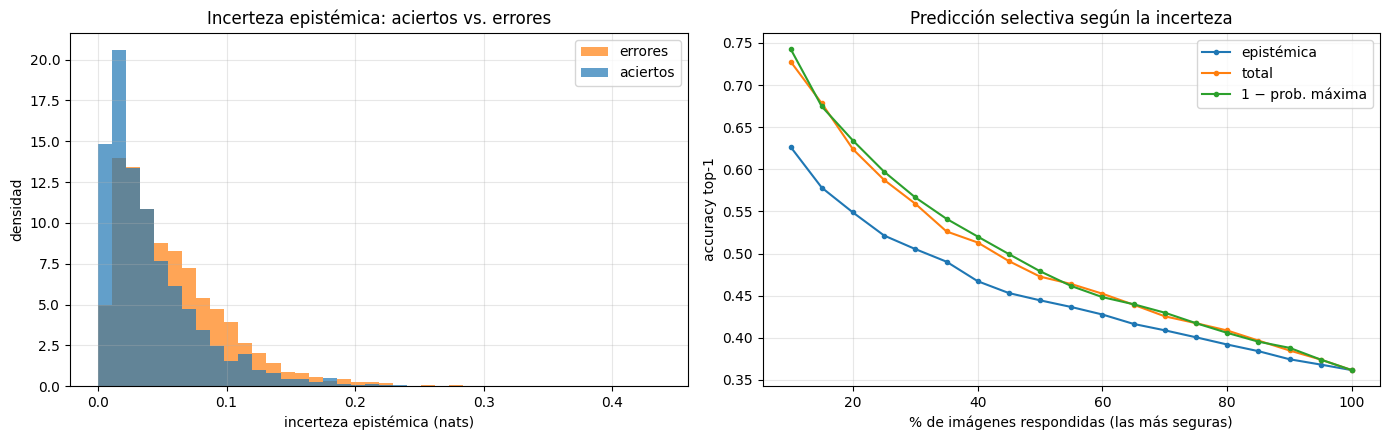

In [8]:
def entropia(p, eje=-1):
    return -(p * np.log(np.clip(p, 1e-12, None))).sum(axis=eje)


inc_total = entropia(p_ens)
inc_aleatorica = entropia(probs).mean(axis=0)
inc_epistemica = inc_total - inc_aleatorica
pred_ens = p_ens.argmax(axis=1)
acierto = pred_ens == real

por_imagen = meta_val[["image_id", "panoid", "country_code", *COLS_COORDENADAS]].copy()
por_imagen["celda_real"] = real
por_imagen["celda_predicha"] = pred_ens
por_imagen["acierto"] = acierto
por_imagen["error_km"] = dist_val[np.arange(len(real)), pred_ens]
por_imagen["incerteza_total"] = inc_total
por_imagen["incerteza_aleatorica"] = inc_aleatorica
por_imagen["incerteza_epistemica"] = inc_epistemica
por_imagen.to_csv(ruta_salida / "incerteza_por_imagen.csv", index=False)

display(por_imagen.groupby("acierto")[["incerteza_total", "incerteza_aleatorica", "incerteza_epistemica"]]
        .mean().rename(index={True: "aciertos", False: "errores"}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist([inc_epistemica[acierto], inc_epistemica[~acierto]], bins=40, label=["aciertos", "errores"],
             density=True, alpha=0.7, histtype="stepfilled")
axes[0].set(xlabel="incerteza epistémica (nats)", ylabel="densidad", title="Incerteza epistémica: aciertos vs. errores")
axes[0].legend()
# Predicción selectiva: responder solo el x% más seguro según cada medida de incerteza.
coberturas = np.linspace(0.1, 1.0, 19)
for nombre, puntaje in (("epistémica", inc_epistemica), ("total", inc_total), ("1 − prob. máxima", 1 - p_ens.max(axis=1))):
    orden = np.argsort(puntaje)
    axes[1].plot(coberturas * 100, [acierto[orden[:max(1, int(c * len(orden)))]].mean() for c in coberturas],
                 marker=".", label=nombre)
axes[1].set(xlabel="% de imágenes respondidas (las más seguras)", ylabel="accuracy top-1",
            title="Predicción selectiva según la incerteza")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_salida / "incerteza_aciertos_y_seleccion.png", dpi=160)
plt.show()

### Celdas más difíciles según la incerteza epistémica

Se agrupa por **celda real** (dónde están las fotos) y se promedia la incerteza epistémica de sus imágenes de
validación. Una celda con epistémica alta es una región donde los snapshots no se ponen de acuerdo: el modelo
"no sabe" qué hacer con esas fotos (en términos de la Unidad 6, es donde más rendiría juntar datos). Se muestran
también la aleatórica, la accuracy y el error para ver si la dificultad viene del desacuerdo o de la ambigüedad.
Las celdas sin imágenes de validación quedan fuera, y solo entran al ranking las que tienen al menos
`MIN_IMAGENES_CELDA` imágenes (con menos, el promedio es ruido); las demás igual aparecen en el mapa.

In [9]:
def paises_principales(codigos, n=2):
    codigos = codigos.dropna().astype(str).str.strip().str.upper()
    frecuencias = codigos[codigos != ""].value_counts(normalize=True).head(n)
    return ", ".join(f"{pais} ({frac:.0%})" for pais, frac in frecuencias.items())


por_celda = por_imagen.groupby("celda_real").agg(
    n_val=("acierto", "size"), incerteza_epistemica=("incerteza_epistemica", "mean"),
    incerteza_aleatorica=("incerteza_aleatorica", "mean"), incerteza_total=("incerteza_total", "mean"),
    accuracy=("acierto", "mean"), error_mediano_km=("error_km", "median"),
    paises=("country_code", paises_principales))
por_celda["lat"] = coords_prototipos[por_celda.index, 0]
por_celda["lon"] = coords_prototipos[por_celda.index, 1]
por_celda = por_celda.sort_values("incerteza_epistemica", ascending=False)
# Ranking solo entre celdas con suficientes imágenes; el resto queda sin puesto (NaN) pero sigue en el mapa.
rankeable = por_celda["n_val"] >= MIN_IMAGENES_CELDA
por_celda["ranking_epistemica"] = np.nan
por_celda.loc[rankeable, "ranking_epistemica"] = np.arange(1, rankeable.sum() + 1)
por_celda.to_csv(ruta_salida / "incerteza_por_celda.csv")

corr = por_celda.loc[rankeable, ["incerteza_epistemica", "accuracy"]].corr(method="spearman").iloc[0, 1]
print(f"Celdas en el ranking (≥ {MIN_IMAGENES_CELDA} imágenes): {rankeable.sum()} de {len(por_celda)}")
print(f"Spearman entre epistémica media y accuracy por celda: {corr:.2f}")
print(f"Las {TOP_CELDAS} celdas con mayor incerteza epistémica media:")
display(por_celda[rankeable].head(TOP_CELDAS).drop(columns=["lat", "lon", "ranking_epistemica"]).round(3))

Celdas en el ranking (≥ 20 imágenes): 62 de 66
Spearman entre epistémica media y accuracy por celda: -0.26
Las 10 celdas con mayor incerteza epistémica media:


,n_val,incerteza_epistemica,incerteza_aleatorica,incerteza_total,accuracy,error_mediano_km,paises
celda_real,,,,,,,
41,80,0.086,2.089,2.175,0.325,2833.957,MX (100%)
63,184,0.078,1.902,1.980,0.408,1924.002,"TH (65%), VN (24%)"
37,40,0.077,1.689,1.766,0.200,3443.170,"PE (60%), EC (30%)"
61,28,0.076,2.109,2.185,0.179,4540.328,MX (100%)
11,28,0.074,1.934,2.008,0.321,3091.175,"TW (71%), PH (29%)"
3,56,0.071,1.613,1.684,0.464,2229.881,"CO (50%), CR (36%)"
29,32,0.071,1.972,2.043,0.188,1694.123,BR (100%)
18,128,0.071,2.102,2.173,0.266,2162.650,"ES (78%), PT (22%)"
9,64,0.071,1.898,1.968,0.359,1008.595,"TR (81%), RU (12%)"


In [10]:
# Mapa: prototipos coloreados por incerteza epistémica media; tamaño según imágenes de validación.
# Las TOP_CELDAS más inciertas llevan su número de celda y borde negro grueso.
estilo_geo = dict(projection_type="natural earth", showland=True, landcolor="#f1ede4", showocean=True,
                  oceancolor="#dfeaf2", showcountries=True, countrycolor="#bbbbbb", showcoastlines=True,
                  coastlinecolor="#888888")
es_top = por_celda["ranking_epistemica"] <= TOP_CELDAS
hover = ("Celda %{customdata[0]} (puesto %{customdata[1]})<br>Epistémica %{customdata[2]:.3f}"
         "<br>Aleatórica %{customdata[3]:.3f}<br>Accuracy %{customdata[4]:.2f}<br>Error mediano %{customdata[5]:.0f} km"
         "<br>N val %{customdata[6]}<br>%{customdata[7]}<extra></extra>")
puesto = [f"{int(r)}" if pd.notna(r) else f"sin ranking: < {MIN_IMAGENES_CELDA} imágenes"
          for r in por_celda["ranking_epistemica"]]
datos_hover = np.column_stack([por_celda.index, puesto, por_celda["incerteza_epistemica"],
                               por_celda["incerteza_aleatorica"], por_celda["accuracy"], por_celda["error_mediano_km"],
                               por_celda["n_val"], por_celda["paises"]])
fig = go.Figure(go.Scattergeo(
    lat=por_celda["lat"], lon=por_celda["lon"], mode="markers+text",
    text=np.where(es_top, por_celda.index.astype(str), ""), textposition="top center",
    marker=dict(size=8 + 22 * por_celda["n_val"] / por_celda["n_val"].max(), color=por_celda["incerteza_epistemica"],
                colorscale="YlOrRd", colorbar=dict(title="Epistémica<br>media (nats)"),
                line=dict(width=np.where(es_top, 2.5, 0.5), color="black")),
    customdata=datos_hover, hovertemplate=hover, showlegend=False))
sin_val = sorted(set(range(NUM_CLASES)) - set(por_celda.index))
if sin_val:
    fig.add_trace(go.Scattergeo(lat=coords_prototipos[sin_val, 0], lon=coords_prototipos[sin_val, 1], mode="markers",
                                marker=dict(size=7, color="lightgray", line=dict(width=0.5, color="black")),
                                name="sin validación", hovertemplate="Sin imágenes de validación<extra></extra>"))
fig.update_geos(**estilo_geo)
fig.update_layout(title=f"Incerteza epistémica media por celda (ensamble de {M} snapshots; "
                        f"número = las {TOP_CELDAS} más inciertas)",
                  height=620, margin=dict(l=0, r=0, t=50, b=0), legend=dict(x=0.01, y=0.01))
fig.write_html(ruta_salida / "mapa_incerteza_epistemica_por_celda.html")
fig.show()

In [11]:
# Mapa por imagen: cada foto de validación en su ubicación real, coloreada por su incerteza epistémica.
orden = np.argsort(inc_epistemica)  # Las más inciertas se dibujan encima.
fig = go.Figure(go.Scattergeo(
    lat=por_imagen["latitude"].to_numpy()[orden], lon=por_imagen["longitude"].to_numpy()[orden], mode="markers",
    marker=dict(size=4, color=inc_epistemica[orden], colorscale="YlOrRd", opacity=0.8,
                colorbar=dict(title="Epistémica<br>(nats)")),
    customdata=np.column_stack([por_imagen["celda_real"].to_numpy()[orden], por_imagen["celda_predicha"].to_numpy()[orden],
                                por_imagen["error_km"].to_numpy()[orden], por_imagen["country_code"].to_numpy()[orden]]),
    hovertemplate=("Celda real %{customdata[0]} → predicha %{customdata[1]}<br>Error %{customdata[2]:.0f} km"
                   "<br>%{customdata[3]}<br>Epistémica %{marker.color:.3f}<extra></extra>")))
fig.update_geos(**estilo_geo)
fig.update_layout(title="Incerteza epistémica por imagen de validación", height=620, margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(ruta_salida / "mapa_incerteza_epistemica_por_imagen.html")
fig.show()
print(f"Resultados guardados en {ruta_salida}")

Resultados guardados en C:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18_IMAGENET_celdas_k70_haversine_aug_sam\20261112_114257_997479\snapshot_ensemble
